# Fine-grained rollouts — cross-agent summary

Summarises the 2,700 episodes collected by `scripts/collect_fine_grained.py`
(3 regimes × 9 policies × 100 episodes, seeds 90000–90099):

* rule-based: `random`, `fixedspread`, `as`, `glft`
* trained (each regime's best checkpoint, handcrafted encoder, greedy): `dqn`, `qrdqn` (α=0.25), `iqn` (α=0.25), `ppo`, `sarsa`

Seeds 90000–90059 are the **discovery** block and 90060–90099 the **confirmation** block.
The same seed is used across policies, so comparisons can be paired by seed.

**P&L convention** (same as `training/evaluate.py`): per step
`spread_pnl + prev_inventory × (mid − prev_mid)`; episode P&L is the sum.
The `cash` column is *not* used: the env clamps inventory to ±Q_max but not cash, so
`cash + inv × mid` is wrong in episodes where the clamp binds.

This is a descriptive summary of one run per cell (single checkpoint per agent/regime, seed 42 training),
not a re-estimate of the paper's multi-seed results.

In [1]:
import glob, json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
ROOT = "../data/processed/fine_grained" if os.path.exists("../data/processed/fine_grained") else "data/processed/fine_grained"
REGIMES = ["low_vol", "normal", "high_vol"]
RULE = ["random", "fixedspread", "as", "glft"]
RL = ["dqn", "qrdqn", "iqn", "ppo", "sarsa"]
POLICIES = RULE + RL
DISCOVERY_MAX_SEED = 90059

dirs = sorted(glob.glob(f"{ROOT}/*/"))
steps = pd.concat([pd.read_parquet(d + "steps.parquet") for d in dirs], ignore_index=True)
grid = pd.concat([pd.read_parquet(d + "grid_60s.parquet",
        columns=["seed","regime","policy","step","t_s","inventory_shares","bid_offset","ask_offset","bid_filled","ask_filled","spread","mid"])
        for d in dirs], ignore_index=True)
fills = pd.concat([pd.read_parquet(d + "fills.parquet") for d in dirs], ignore_index=True)
print(len(dirs), "chunks;", len(steps), "decision rows;", len(fills), "fills")

135 chunks; 1053000 decision rows; 397731 fills


## 1. Integrity checks

In [2]:
key = ["regime", "policy", "seed"]
ep_rows = steps.groupby(key).size()
checks = pd.DataFrame({
    "episodes per (regime, policy)": steps.groupby(["regime","policy"]).seed.nunique().unstack().reindex(columns=POLICIES).loc[REGIMES].stack().describe()[["min","max"]],
}).T
print("episodes per cell:", dict(zip(["min","max"], steps.groupby(["regime","policy"]).seed.nunique().agg(["min","max"]))))
print("steps per episode:", dict(zip(["min","max"], ep_rows.agg(["min","max"]))))
print("duplicate (regime,policy,seed,step):", steps.duplicated(key + ["step"]).sum())
print("seed range:", steps.seed.min(), "-", steps.seed.max())
print("NaN counts in steps:"); print(steps.isna().sum()[lambda s: s > 0].to_dict() or "none")
print("inventory range:", steps.inventory.min(), steps.inventory.max())
bad = [(r, p) for r in REGIMES for p in POLICIES if not ((steps.regime==r)&(steps.policy==p)).any()]
print("missing cells:", bad or "none")

episodes per cell: {'min': 100, 'max': 100}
steps per episode: {'min': 390, 'max': 390}
duplicate (regime,policy,seed,step): 0
seed range: 90000 - 90099
NaN counts in steps:


none
inventory range: -1000 1000


missing cells: none


## 2. Per-episode metrics

In [3]:
steps = steps.sort_values(key + ["step"]).reset_index(drop=True)
g = steps.groupby(key)
steps["prev_inv"] = g.inventory.shift(1).fillna(0)
steps["prev_mid"] = g.mid_price.shift(1)
steps["step_pnl"] = steps.spread_pnl + steps.prev_inv * (steps.mid_price - steps.prev_mid).fillna(0)
steps["at_limit"] = steps.inventory.abs() >= 1000
steps["both_filled"] = (steps.bid_filled > 0) & (steps.ask_filled > 0)

ep = steps.groupby(key).agg(
    pnl=("step_pnl", "sum"),
    spread_pnl=("spread_pnl", "sum"),
    final_inv=("inventory", "last"),
    max_abs_inv=("inventory", lambda x: x.abs().max()),
    mean_abs_inv=("inventory", lambda x: x.abs().mean()),
    frac_at_limit=("at_limit", "mean"),
    bid_fill_sh=("bid_filled", "sum"),
    ask_fill_sh=("ask_filled", "sum"),
    mean_bid_off=("bid_offset", "mean"),
    mean_ask_off=("ask_offset", "mean"),
    reward=("reward", "sum"),
).reset_index()
ep["traded_sh"] = ep.bid_fill_sh + ep.ask_fill_sh
ep["block"] = np.where(ep.seed <= DISCOVERY_MAX_SEED, "discovery", "confirmation")
ep["inv_pnl"] = ep.pnl - ep.spread_pnl
ep.head()

,regime,policy,seed,pnl,spread_pnl,final_inv,max_abs_inv,mean_abs_inv,frac_at_limit,bid_fill_sh,ask_fill_sh,mean_bid_off,mean_ask_off,reward,traded_sh,block,inv_pnl
0,high_vol,as,90000,1102.615,-1200.865,400,500,255.215385,0.0,3790,3442,30.0,30.0,-1978.323188,7232,discovery,2303.480
1,high_vol,as,90001,-365.665,-1298.255,-500,500,325.800000,0.0,3625,4192,30.0,30.0,-5135.432765,7817,discovery,932.590
2,high_vol,as,90002,-264.560,-904.210,-500,500,340.256410,0.0,2258,3100,30.0,30.0,-4443.414113,5358,discovery,639.650
3,high_vol,as,90003,-4344.065,-2536.350,-300,500,286.043590,0.0,4622,4834,30.0,30.0,-10182.813609,9456,discovery,-1807.715
4,high_vol,as,90004,-6262.820,-769.360,-200,500,364.523077,0.0,1600,4259,30.0,30.0,-12378.349596,5859,discovery,-5493.460


## 3. Summary table — regime × policy

`pnl_se` is the standard error over the 100 episodes. `cvar10` is the mean of the worst 10% of episode P&Ls (i.e. the worst 10 episodes).
`sharpe_ep` is mean/std of episode P&L (not annualised). `spread_pnl` is the half-spread captured on fills; `inv_pnl` is the rest (inventory × mid moves).

In [4]:
def cvar(x, a=0.10):
    x = np.sort(np.asarray(x)); k = max(1, int(np.ceil(a * len(x)))); return x[:k].mean()

def summarise(df):
    return pd.Series({
        "n": len(df), "pnl_mean": df.pnl.mean(), "pnl_se": df.pnl.std(ddof=1) / np.sqrt(len(df)),
        "pnl_median": df.pnl.median(), "pnl_std": df.pnl.std(ddof=1), "cvar10": cvar(df.pnl),
        "sharpe_ep": df.pnl.mean() / df.pnl.std(ddof=1), "spread_pnl": df.spread_pnl.mean(), "inv_pnl": df.inv_pnl.mean(),
        "mean_abs_inv": df.mean_abs_inv.mean(), "max_abs_inv": df.max_abs_inv.mean(),
        "frac_at_limit": df.frac_at_limit.mean(), "traded_sh": df.traded_sh.mean(),
        "bid_off": df.mean_bid_off.mean(), "ask_off": df.mean_ask_off.mean(),
    })

summary = ep.groupby(["regime", "policy"]).apply(summarise, include_groups=False)
summary = summary.reindex(pd.MultiIndex.from_product([REGIMES, POLICIES]))
summary.round(2)

n  pnl_mean  pnl_se  pnl_median  pnl_std    cvar10  sharpe_ep  spread_pnl  inv_pnl  mean_abs_inv  max_abs_inv  frac_at_limit  traded_sh  bid_off  ask_off
low_vol  random       100.0     35.89   42.29      -36.27   422.95   -621.97       0.08      -35.13    71.02        372.10       819.39           0.03    6926.32    49.96    50.11
         fixedspread  100.0    174.43   27.00      116.50   269.96    -60.49       0.65       37.14   137.29        103.10       197.41           0.00     494.58    30.00    30.00
         as           100.0    563.60   40.21      627.12   402.06   -340.77       1.40      -47.00   610.60        381.48       858.48           0.04    7359.12    10.00    10.00
         glft         100.0    545.99   36.00      617.95   360.03   -221.50       1.52      -49.16   595.16        362.09       856.04           0.00    7539.65    10.41    10.33
         dqn          100.0   -102.48   64.79      -54.05   647.89  -1239.06      -0.16       21.60  -124.08        885.27      1000.00           0.76   12780.52    34.38    39.57
         qrdqn        100.0   1021.37   35.35     1034.94   353.47    382.35       2.89       59.93   961.44        187.70       638.39           0.00   17485.19    44.21    40.76
         iqn          100.0    422.75   21.75      403.02   217.47    153.04       1.94       66.39   356.37         80.04       239.21           0.00    6911.38    54.48    65.24
         ppo          100.0    104.27   40.04       61.82   400.38   -548.79       0.26      -52.37   156.65        356.15       789.98           0.03    8959.06    47.21    59.96
         sarsa        100.0    136.32   39.92       57.73   399.24   -217.66       0.34       39.82    96.51         96.23       429.58           0.00    2203.06    59.81    56.82
normal   random       100.0   -330.80  124.88     -234.38  1248.78  -2835.50      -0.26      -96.09  -234.72        406.38       847.27           0.05    7517.11    49.96    50.11
         fixedspread  100.0   -121.77   86.25       33.99   862.46  -2064.95      -0.14        6.34  -128.11        238.99       470.20           0.02    1215.50    30.00    30.00
         as           100.0  -1124.18  146.71    -1070.16  1467.09  -3945.74      -0.77     -364.47  -759.71        499.73       995.36           0.12   12141.21    10.00    10.00
         glft         100.0  -1204.42  127.04    -1012.07  1270.36  -3602.56      -0.95     -315.27  -889.16        491.26       990.17           0.04   10897.72    14.64    14.38
         dqn          100.0   2351.83   75.19     2388.33   751.92    964.79       3.13      319.08  2032.75        269.24       793.48           0.00   23631.09    28.40    32.33
         qrdqn        100.0   1502.14   38.97     1510.58   389.67    877.38       3.85      177.29  1324.85        131.49       290.91           0.00   11648.17    52.97    42.15
         iqn          100.0   -125.99  148.98      -72.50  1489.85  -2849.31      -0.08       23.34  -149.32        463.98       649.09           0.04    1808.30    48.35    47.21
         ppo          100.0   -283.11  143.63     -233.60  1436.32  -3115.09      -0.20      -78.80  -204.31        378.54       798.17           0.04    6067.02    44.21    57.56
         sarsa        100.0    109.36   98.77       44.67   987.74  -1456.63       0.11        5.53   103.83        195.49       536.26           0.02    2523.79    54.04    58.89
high_vol random       100.0  -4320.39  282.88    -4267.69  2828.79  -9729.27      -1.53    -1174.70 -3145.68        275.99       500.00           0.00   11205.39    49.96    50.11
         fixedspread  100.0  -4053.87  344.54    -3941.12  3445.41 -10730.39      -1.18    -1404.95 -2648.92        311.03       499.84           0.00    8060.88    30.00    30.00
         as           100.0  -4053.87  344.54    -3941.12  3445.41 -10730.39      -1.18    -1404.95 -2648.92        311.03       499.84           0.00    8060.88    30.00    30.00
         glft         100.0  -4053.87  344.54    -3941.12  3445.41

### P&L (mean ± SE) by regime

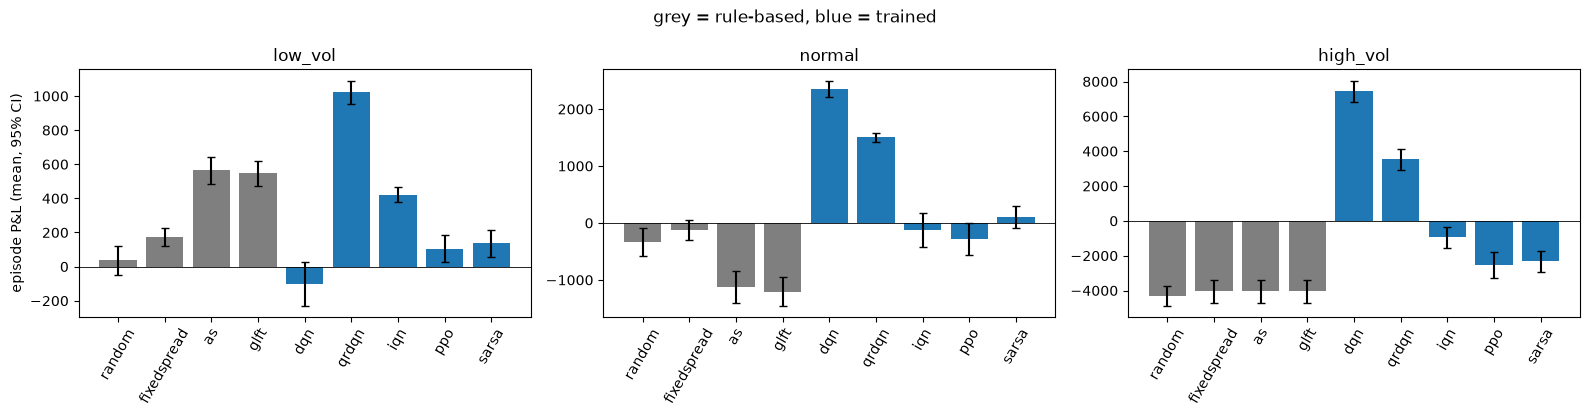

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=False)
cols = {p: ("tab:gray" if p in RULE else "tab:blue") for p in POLICIES}
for ax, r in zip(axes, REGIMES):
    s = summary.loc[r]
    ax.bar(s.index, s.pnl_mean, yerr=1.96 * s.pnl_se, color=[cols[p] for p in s.index], capsize=3)
    ax.axhline(0, color="k", lw=.6); ax.set_title(r); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("episode P&L (mean, 95% CI)")
fig.suptitle("grey = rule-based, blue = trained"); fig.tight_layout(); plt.show()

### P&L distributions

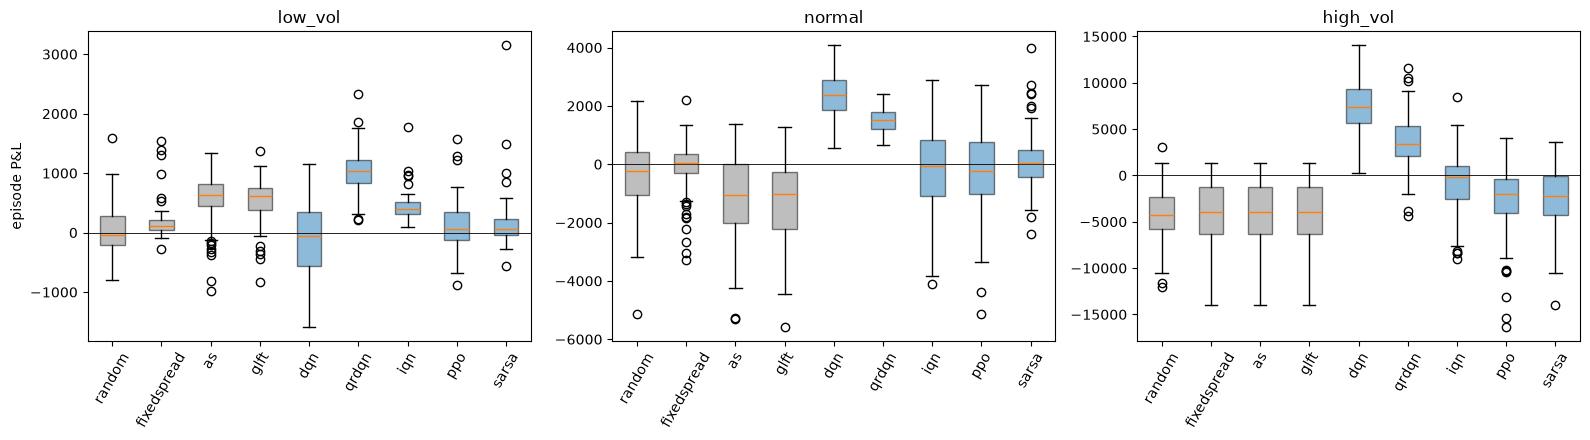

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, r in zip(axes, REGIMES):
    data = [ep[(ep.regime == r) & (ep.policy == p)].pnl.values for p in POLICIES]
    bp = ax.boxplot(data, tick_labels=POLICIES, showfliers=True, patch_artist=True)
    for patch, p in zip(bp["boxes"], POLICIES): patch.set_facecolor(cols[p]); patch.set_alpha(.5)
    ax.axhline(0, color="k", lw=.6); ax.set_title(r); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("episode P&L"); fig.tight_layout(); plt.show()

### Risk–return and inventory

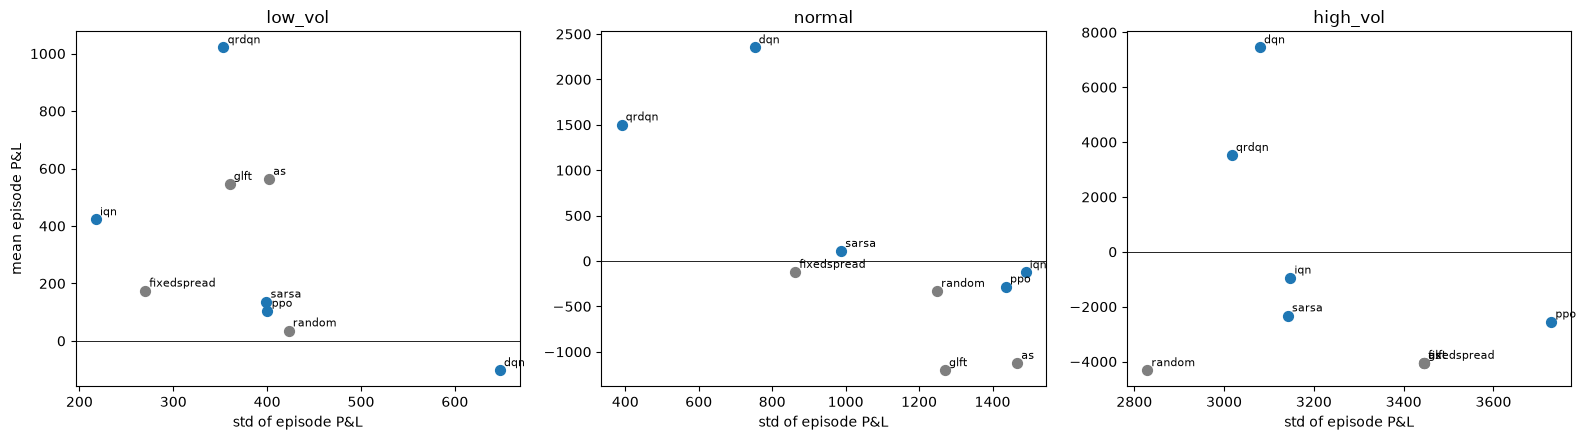

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=False, sharey=False)
for ax, r in zip(axes, REGIMES):
    s = summary.loc[r]
    for p in POLICIES:
        ax.scatter(s.loc[p, "pnl_std"], s.loc[p, "pnl_mean"], c=cols[p], s=50)
        ax.annotate(p, (s.loc[p, "pnl_std"], s.loc[p, "pnl_mean"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, color="k", lw=.6); ax.set_title(r); ax.set_xlabel("std of episode P&L")
axes[0].set_ylabel("mean episode P&L"); fig.tight_layout(); plt.show()

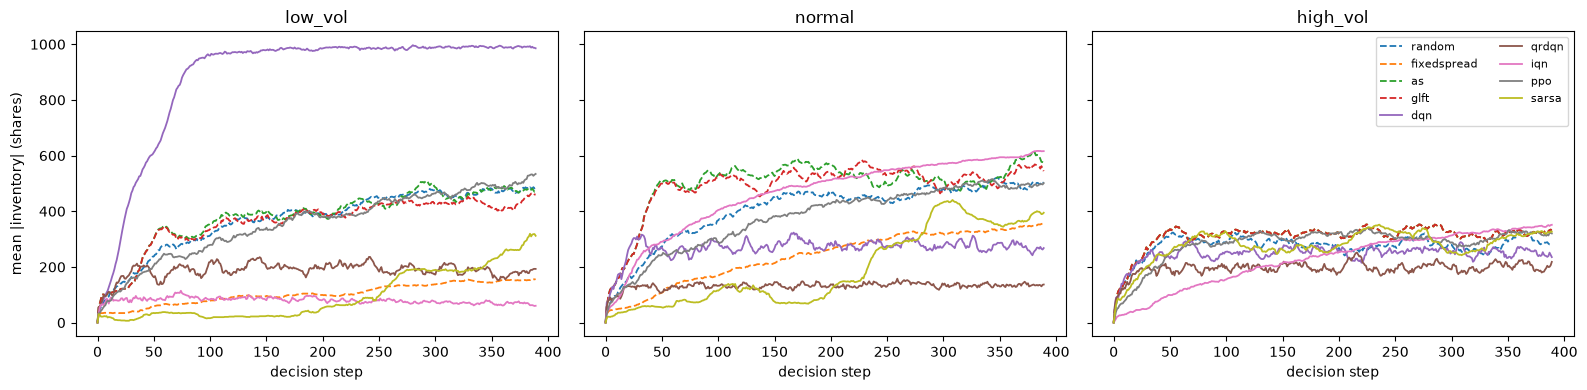

In [8]:
# mean |inventory| through the session
grid["abs_inv"] = grid.inventory_shares.abs()
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, r in zip(axes, REGIMES):
    for p in POLICIES:
        d = grid[(grid.regime == r) & (grid.policy == p)].groupby("step").abs_inv.mean()
        ax.plot(d.index, d.values, label=p, ls="-" if p in RL else "--", lw=1.3)
    ax.set_title(r); ax.set_xlabel("decision step")
axes[0].set_ylabel("mean |inventory| (shares)"); axes[-1].legend(ncol=2, fontsize=8); fig.tight_layout(); plt.show()

## 4. Discovery vs confirmation blocks

Does the ranking found on seeds 90000–90059 hold on the untouched 90060–90099 block?

In [9]:
blk = ep.groupby(["regime", "policy", "block"]).pnl.mean().unstack("block").reindex(pd.MultiIndex.from_product([REGIMES, POLICIES]))
rows = []
for r in REGIMES:
    b = blk.loc[r]
    rho, pv = stats.spearmanr(b.discovery, b.confirmation)
    rows.append(dict(regime=r, spearman=rho, p=pv,
                     top3_disc=list(b.discovery.nlargest(3).index), top3_conf=list(b.confirmation.nlargest(3).index)))
print(pd.DataFrame(rows).round(3).to_string(index=False))
blk.round(1)

  regime  spearman     p           top3_disc           top3_conf
 low_vol     1.000 0.000   [qrdqn, as, glft]   [qrdqn, as, glft]
  normal     0.883 0.002 [dqn, qrdqn, sarsa] [dqn, qrdqn, sarsa]
high_vol     0.897 0.001   [dqn, qrdqn, iqn]   [dqn, qrdqn, iqn]


block                 confirmation  discovery
low_vol  random               10.5       52.8
         fixedspread         129.9      204.1
         as                  629.2      519.9
         glft                592.7      514.9
         dqn                   9.1     -176.9
         qrdqn               998.7     1036.5
         iqn                 395.7      440.8
         ppo                  49.4      140.8
         sarsa               116.5      149.6
normal   random             -446.2     -253.9
         fixedspread        -279.9      -16.3
         as                 -985.0    -1217.0
         glft              -1048.3    -1308.5
         dqn                2380.0     2333.0
         qrdqn              1445.2     1540.1
         iqn                -275.9      -26.0
         ppo                -755.7       32.0
         sarsa                31.9      161.0
high_vol random            -4918.3    -3921.8
         fixedspread       -4167.7    -3978.0
         as                -4167.7    -3978.0
         glft              -4167.7    -3978.0
         dqn                7748.6     7248.4
         qrdqn              4201.2     3072.7
         iqn                -925.9     -958.3
         ppo               -2628.4    -2494.3
         sarsa             -2517.4    -2193.8

## 5. Paired comparison against GLFT

Same seeds ⇒ paired differences. 95% CI by bootstrap over episodes (10,000 resamples).

In [10]:
rng = np.random.default_rng(0)
piv = ep.pivot_table(index=["regime", "seed"], columns="policy", values="pnl")
rows = []
for r in REGIMES:
    for p in POLICIES:
        if p == "glft": continue
        d = (piv.loc[r][p] - piv.loc[r]["glft"]).values
        bs = rng.choice(d, (10000, len(d))).mean(1)
        rows.append(dict(regime=r, policy=p, mean_diff=d.mean(), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                         beats_glft_frac=(d > 0).mean()))
paired = pd.DataFrame(rows)
paired["sig"] = np.where(paired.lo > 0, "better", np.where(paired.hi < 0, "worse", "ns"))
paired.round(2)

,regime,policy,mean_diff,lo,hi,beats_glft_frac,sig
0,low_vol,random,-510.10,-617.71,-395.03,0.14,worse
1,low_vol,fixedspread,-371.56,-454.95,-285.15,0.19,worse
2,low_vol,as,17.61,-35.10,71.50,0.30,ns
3,low_vol,dqn,-648.47,-786.46,-515.03,0.19,worse
4,low_vol,qrdqn,475.38,387.95,564.12,0.87,better
5,low_vol,iqn,-123.24,-197.79,-40.18,0.28,worse
6,low_vol,ppo,-441.72,-541.18,-337.91,0.16,worse
7,low_vol,sarsa,-409.67,-511.07,-297.67,0.13,worse
8,normal,random,873.62,583.30,1158.80,0.75,better
9,normal,fixedspread,1082.65,834.18,1330.11,0.82,better


## 6. Quoting behaviour

Offsets are the agent's chosen distance from mid, in the env's tick units. `skew_slope` is the OLS slope of
`(ask_offset − bid_offset)` on inventory/1000. A textbook inventory-skewing maker quotes the ask closer and the bid
further when long, so its slope is **negative**; a more negative slope means a stronger mean-reverting skew, zero means symmetric quotes.

In [11]:
g2 = grid.dropna(subset=["bid_offset", "ask_offset"]).copy()
g2["quote_skew"] = g2.ask_offset - g2.bid_offset
g2["inv_k"] = g2.inventory_shares / 1000
rows = []
for (r, p), d in g2.groupby(["regime", "policy"]):
    sl = stats.linregress(d.inv_k, d.quote_skew)
    rows.append(dict(regime=r, policy=p, bid_off=d.bid_offset.mean(), ask_off=d.ask_offset.mean(),
                     off_std=pd.concat([d.bid_offset, d.ask_offset]).std(),
                     distinct_actions=d[["bid_offset", "ask_offset"]].drop_duplicates().shape[0],
                     skew_slope=sl.slope, skew_r2=sl.rvalue ** 2))
quote = pd.DataFrame(rows).set_index(["regime", "policy"]).reindex(pd.MultiIndex.from_product([REGIMES, POLICIES]))
quote.round(3)

bid_off  ask_off  off_std  distinct_actions  skew_slope  skew_r2
low_vol  random        49.962   50.098   31.652               121       3.104    0.001
         fixedspread   30.000   30.000    0.000                 1       0.000      NaN
         as            10.000   10.000    0.000                 1       0.000      NaN
         glft          10.395   10.332    5.973                 7      -4.027    0.040
         dqn           34.395   39.569   31.516                46     -12.336    0.009
         qrdqn         44.212   40.755   34.139                36      36.701    0.016
         iqn           54.466   65.217   31.266                34    -129.787    0.052
         ppo           47.215   59.969   34.217               114       4.860    0.003
         sarsa         59.807   56.809   28.660               119       8.770    0.002
normal   random        49.962   50.098   31.652               121       3.383    0.001
         fixedspread   30.000   30.000    0.000                 1       0.000      NaN
         as            10.000   10.000    0.000                 1       0.000      NaN
         glft          14.631   14.371   18.601                 5     -25.674    0.305
         dqn           28.387   32.329   31.129                42     -14.231    0.007
         qrdqn         52.977   42.152   31.652                45       7.423    0.000
         iqn           48.351   47.207    9.147                12      -1.356    0.002
         ppo           44.212   57.564   31.661               121       3.028    0.001
         sarsa         54.020   58.901   27.215               120     -10.219    0.006
high_vol random        49.962   50.098   31.652               121       7.991    0.003
         fixedspread   30.000   30.000    0.000                 1       0.000      NaN
         as            30.000   30.000    0.000                 1       0.000      NaN
         glft          30.000   30.000    0.000                 1       0.000      NaN
         dqn           46.675   44.129   41.886                31      52.581    0.037
         qrdqn         36.874   32.247   32.780                33      65.228    0.073
         iqn           98.409   74.180   19.168                 6      20.163    0.082
         ppo           56.217   72.791   29.194               121      14.603    0.012
         sarsa         58.305   59.850   28.717               121       4.755    0.001

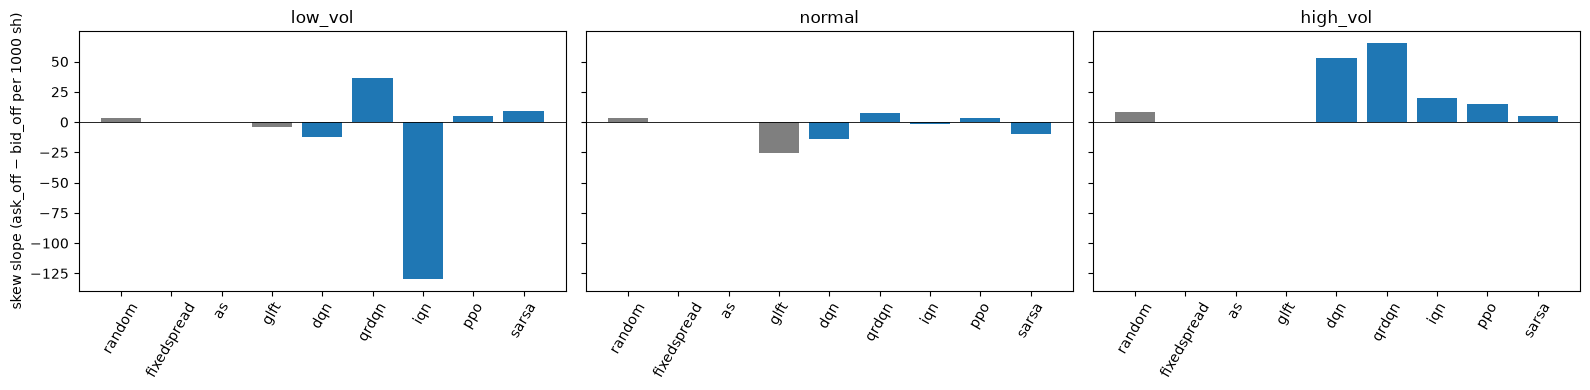

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, r in zip(axes, REGIMES):
    q = quote.loc[r]
    ax.bar(q.index, q.skew_slope, color=[cols[p] for p in q.index]); ax.axhline(0, color="k", lw=.6)
    ax.set_title(r); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("skew slope (ask_off − bid_off per 1000 sh)"); fig.tight_layout(); plt.show()

## 7. Fills

In [13]:
f = fills.groupby(["regime", "policy", "seed"]).agg(n_fills=("quantity", "size"), fill_sh=("quantity", "sum")).reset_index()
ff = f.groupby(["regime", "policy"])[["n_fills", "fill_sh"]].mean().reindex(pd.MultiIndex.from_product([REGIMES, POLICIES]))
ff["bid_share"] = (fills[fills.side == "BID"].groupby(["regime", "policy"]).quantity.sum() / fills.groupby(["regime", "policy"]).quantity.sum())
ff.round(2)

n_fills   fill_sh  bid_share
low_vol  random        124.86   6926.32       0.50
         fixedspread     6.68    526.15       0.52
         as            110.44   7359.12       0.50
         glft          112.96   7539.65       0.50
         dqn           226.84  12780.52       0.83
         qrdqn         321.22  17485.19       0.50
         iqn           124.82   6911.38       0.50
         ppo           161.50   8959.06       0.49
         sarsa          37.96   2203.06       0.54
normal   random        130.22   7517.11       0.51
         fixedspread    16.13   1215.50       0.49
         as            180.24  12141.21       0.49
         glft          162.86  10897.72       0.49
         dqn           424.05  23631.09       0.50
         qrdqn         207.93  11648.17       0.50
         iqn            29.95   1808.30       0.21
         ppo           104.41   6067.02       0.48
         sarsa          41.49   2523.79       0.52
high_vol random        177.18  11205.39       0.50
         fixedspread   109.71   8060.88       0.48
         as            109.71   8060.88       0.48
         glft          109.71   8060.88       0.48
         dqn           391.19  22664.94       0.52
         qrdqn         335.05  19906.04       0.50
         iqn            25.24   1865.67       0.30
         ppo            98.06   6356.85       0.42
         sarsa          97.55   6497.90       0.53

## 8. Consistency with the held-out evaluation

The paper's evaluation (`results/holdout_eval.csv`) uses a different seed block (80042–80056, 15 episodes). If these rollouts are the same
policies in the same environment, mean P&L and the ranking should agree up to sampling noise.

In [14]:
hp = "../results/holdout_eval.csv" if os.path.exists("../results/holdout_eval.csv") else "results/holdout_eval.csv"
ho = pd.read_csv(hp).groupby(["regime", "model"]).final_pnl.mean().unstack("regime")[REGIMES]
here = summary.pnl_mean.unstack(0)[REGIMES]
cmp_ = pd.concat({"held-out (15 ep)": ho.reindex(POLICIES), "these rollouts (100 ep)": here.reindex(POLICIES)}, axis=1)
print(cmp_.round(0).to_string())
for r in REGIMES:
    pair = pd.concat([ho[r], here[r]], axis=1, keys=["ho", "here"]).dropna()   # `random` was not in the held-out eval
    print(r, "Spearman rank agreement over %d policies: %.2f" % (len(pair), stats.spearmanr(pair.ho, pair.here)[0]))

            held-out (15 ep)                  these rollouts (100 ep)                 
regime               low_vol  normal high_vol                 low_vol  normal high_vol
random                   NaN     NaN      NaN                    36.0  -331.0  -4320.0
fixedspread            129.0   275.0  -4902.0                   174.0  -122.0  -4054.0
as                     540.0 -1185.0  -4902.0                   564.0 -1124.0  -4054.0
glft                   489.0 -1405.0  -4902.0                   546.0 -1204.0  -4054.0
dqn                     67.0  2146.0   5027.0                  -102.0  2352.0   7448.0
qrdqn                  955.0  1298.0   2359.0                  1021.0  1502.0   3524.0
iqn                    423.0   -86.0   -581.0                   423.0  -126.0   -945.0
ppo                    104.0  -145.0  -1628.0                   104.0  -283.0  -2548.0
sarsa                  101.0   -95.0  -2563.0                   136.0   109.0  -2323.0
low_vol Spearman rank agreement over 8 poli

## 9. What this shows (and doesn't)

* **Integrity.** All 27 cells have 100 episodes × 390 steps, no duplicate keys, no NaNs in `steps`; discovery and confirmation blocks agree
  (Spearman 0.88–1.00 across policies, identical top-3 in every regime). The ranking is stable across seed blocks.
* **Agreement with the paper's held-out evaluation.** Rankings agree with `results/holdout_eval.csv` (section 8), so these rollouts
  are the same policies as the evaluated ones, not a different behaviour caused by the recorder.
* **Trained agents vs the baselines.** In `normal` and `high_vol`, DQN and QR-DQN beat GLFT with paired 95% CIs excluding 0; in `low_vol` only QR-DQN does,
  and AS ≈ GLFT. IQN, PPO and SARSA are positive vs GLFT in `normal`/`high_vol` mostly because GLFT is itself negative there, not because they are profitable
  (their own mean P&L is ≤ ~0 in absolute terms; see the table).
* **DQN vs QR-DQN.** This single-checkpoint run has DQN ahead of QR-DQN in `normal` and `high_vol` on mean P&L, but QR-DQN has the better CVaR/Sharpe in `normal`
  and a far smaller P&L std. DQN's `low_vol` checkpoint sits at the inventory limit 76% of the time and loses. These are one training seed per cell; the paper's multi-seed
  tables remain the authority for claims.
* **`high_vol` baselines are identical.** `fixedspread`, `as` and `glft` all quote a constant 30 (action offset) there, giving identical episodes. The held-out
  evaluation shows the same collapse (−4902 for all three). In `low_vol`/`normal` AS quotes a constant 10 and GLFT adds only a small skew.
* **Quote-skew slopes (section 6) are not interpretable for the trained agents:** R² is ≈ 0 for all but GLFT in `normal` (0.31), because the agents' offsets vary far more than
  inventory explains. Treat the slopes as a diagnostic only.
* **Not covered here:** within-episode (5 s) structure — that is the next step, using `grid_5s` and `book` for the discovery/confirmation analysis.